In [1]:
import functions
import numpy as np
import matplotlib.pyplot as plt

In [26]:
epsilon = 1e-16
R = np.linspace(0 + epsilon, 10, 10000)
theta_ = np.array([0, 15, 30, 45, 60, 75, 90])
theta = theta_*np.pi/180

""" Definimos las constantes """
    
N = 100                # Define la forma del brazo. Se hace que N >> 1 en los modelos?
Rs = 3.5                  # Distancia galactocéntrica en la que el patrón espiral comienza
i0_ = 15.5
i0 = i0_*np.pi/180       # Pitch angle
A = 900/100             # Amplitud en km^2 s^-2 kpc^-1. Multiplicado por 1/100 para que coincidan las unidades
epsilon_s = 1/2.5        # Inverso de la longitud de escala radial

In [27]:
def magnitude(acx, acy): 
    mag = np.sqrt(acx**2 + acy**2)
    return mag

def accTWA(x, y, z): 
    
    R = np.sqrt(x**2 + y**2)
    
    Theta = 2/(N*np.tan(i0))*np.log(1+(R/Rs)**N)
    
    cos_cx = 2 - epsilon_s*(x**2 - y**2)/R - (x**2 - y**2)/R**2 + 4*x*y*R**(N-2)/(np.tan(i0)*(Rs**N + R**N))
    sin_cx = y - epsilon_s*(x**2)*y/R - (x**2 - y**2)*x*R**(N-2)/(np.tan(i0)*(Rs**N + R**N)) - (y*x**2)/(R**2)
    acx = (A/R)*np.exp(-epsilon_s*R)*(x*np.cos(Theta)*cos_cx + 2*np.sin(Theta)*sin_cx)

    cos_cy = -2 - epsilon_s*(x**2 - y**2)/R - (x**2 - y**2)/R**2 + 4*x*y*R**(N-2)/(np.tan(i0)*(Rs**N + R**N))
    sin_cy = x - epsilon_s*x*y**2/R - (x**2 - y**2)*y*R**(N-2)/(np.tan(i0)*(Rs**N + R**N)) - x*y**2/R**2
    acy = (A/R)*np.exp(-epsilon_s*R)*(y*np.cos(Theta)*cos_cy + 2*np.sin(Theta)*sin_cy)

    return acx, acy

def phiTWA(x,y,z):

    R = np.sqrt(x**2 + y**2)
    phi_cos = -A*R*np.exp(-epsilon_s*R)*np.cos(2*np.arctan(y/x) - 2/(N*np.tan(i0))*np.log(1+(R/Rs)**N))
    
    return phi_cos

def phiAS(v):
    m1, b1 = 606., 0.3873
    m2, a2, b2 = 3690., 5.3178, .25
    m3, a3 = 4615., 12.0

    x, y, z = v[0], v[1], v[2]
    R = np.sqrt(x**2 + y**2 + z**2)
    truncation = 100
    R_  = max(R, 1e-6)
    R_ = np.minimum(R_, truncation)
    
    omega = np.sqrt(x**2 + y**2)

    M_R = m3*(R_/a3)**(2.02)/(1 + (R_/a3)**(1.02))
    term1 = -(1.02)/(1 + (100/a3)**(1.02)) + np.log(1 + (100/a3)**(1.02))
    term2 = -(1.02)/(1 + (R_/a3)**(1.02)) + np.log(1 + (R_/a3)**(1.02))
        
    phi1 = -m1/ np.sqrt(R**2 +b1**2)
    phi2 = -m2 / np.sqrt(omega**2 + (a2 + np.sqrt(z**2 + b2**2))**2)
    phi3 = -M_R/R_ - (m3/(1.02 * a3)) * (term1 - term2)

    phi = phi1 + phi2 + phi3
    return phi

sun = np.array([8.5, 0, 0])
phi_sun = phiAS(sun)

forces = {}
radial_forces = {}
azimuthal_forces = {}
phi = {}

for i in range(len(theta)):

    x = R * np.cos(theta[i])
    y = R * np.sin(theta[i])
    z = np.zeros_like(R)

    acx, acy = accTWA(x, y, z)

    phi_ = phiTWA(x, y, z)/np.absolute(phi_sun)*1e2
    mag = magnitude(acx, acy)
    FR = mag*np.cos(theta[i])

    forces[str(theta_[i])] = mag
    radial_forces[str(theta_[i])] = FR
    phi[str(theta_[i])] = phi_

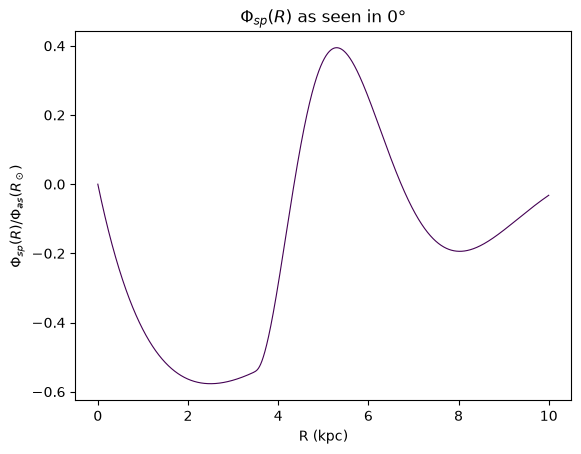

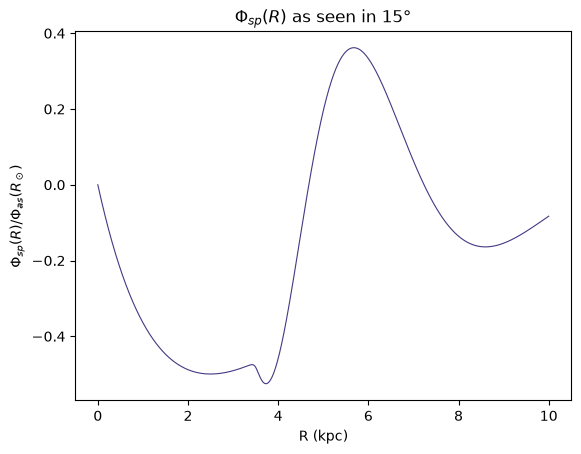

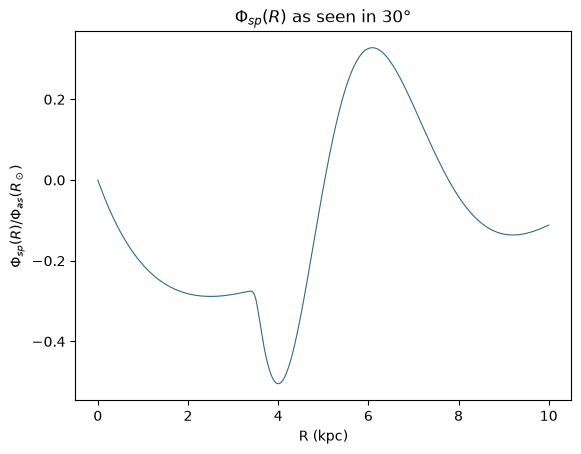

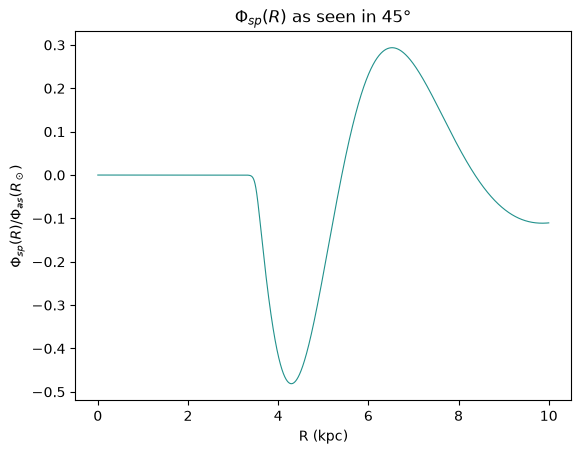

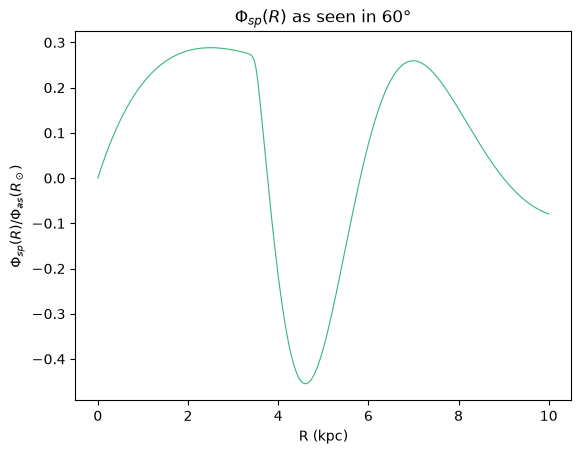

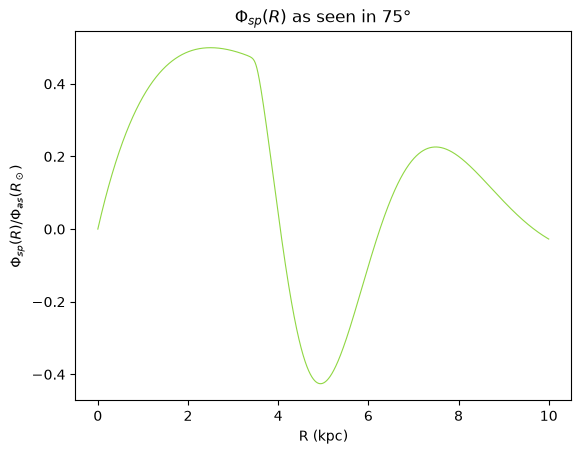

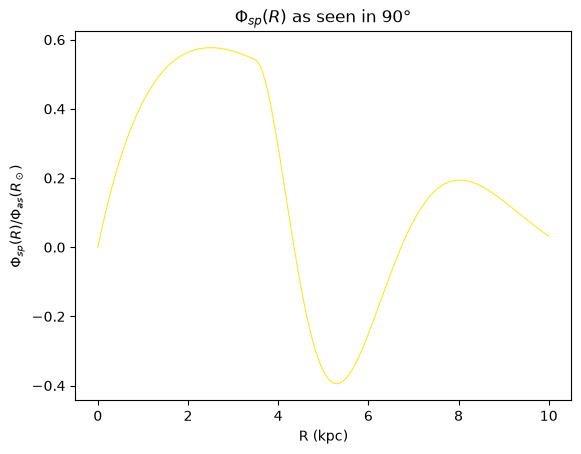

In [28]:
colors = plt.cm.viridis(np.linspace(0, 1, 7))

for i in range(len(theta)):
    plt.figure()
    plt.plot(R, phi[str(theta_[i])], lw = 0.8, color = colors[i])

    plt.xlabel(r"R (kpc)")
    plt.ylabel(r"$\Phi_{sp}(R)/\Phi_{as}(R_\odot)$")
    plt.title(r"$\Phi_{sp}(R)$" + f" as seen in {15*i}°")

    plt.show()

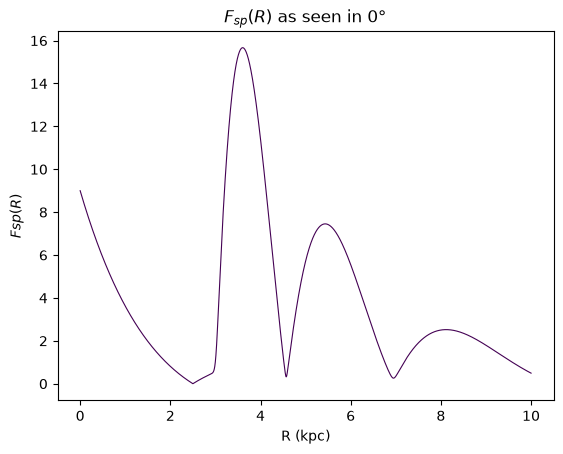

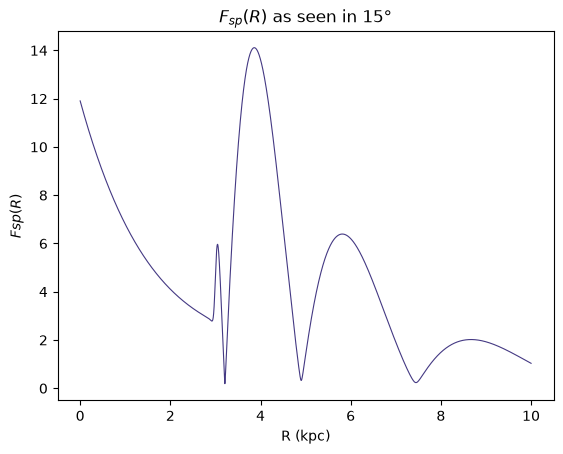

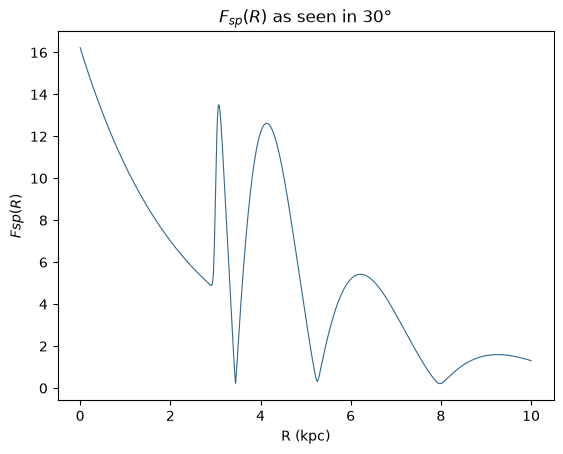

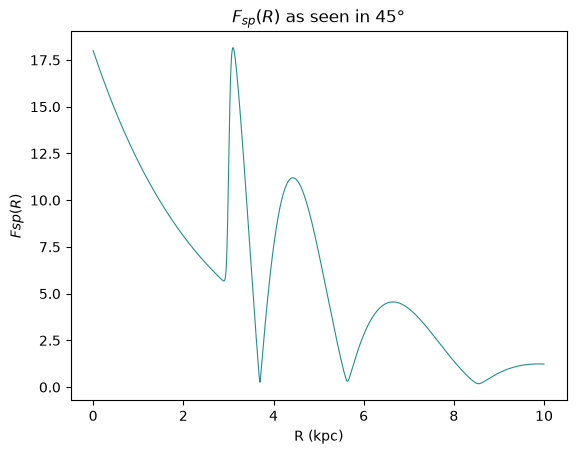

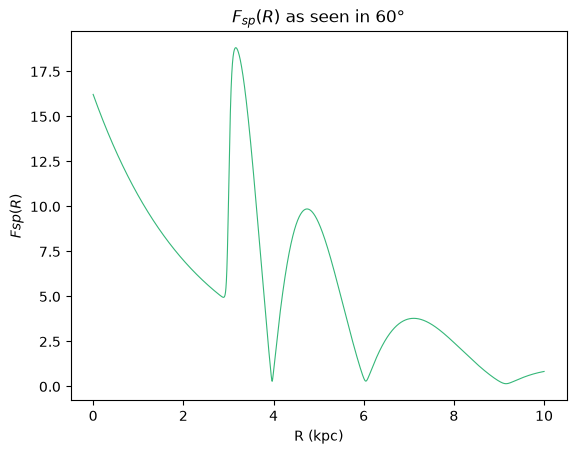

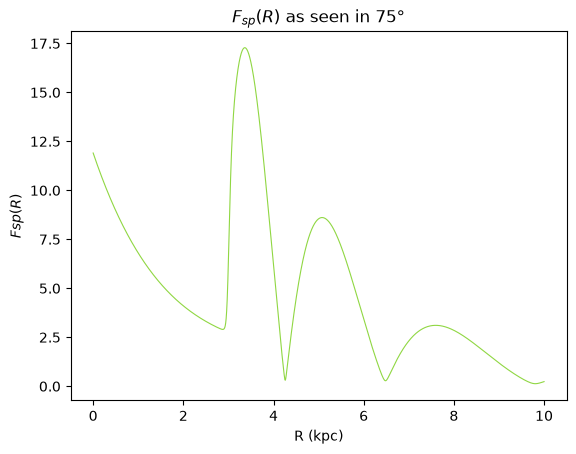

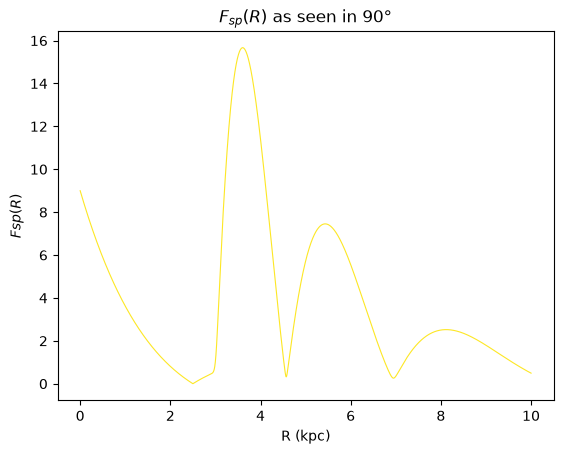

In [23]:
colors = plt.cm.viridis(np.linspace(0, 1, 7))

for i in range(len(theta)):
    plt.figure()
    plt.plot(R, forces[str(theta_[i])], lw = 0.8, color = colors[i])

    plt.xlabel(r"R (kpc)")
    plt.ylabel(r"$F{sp}(R)$")
    plt.title(r"$F_{sp}(R)$" + f" as seen in {15*i}°")

    plt.show()

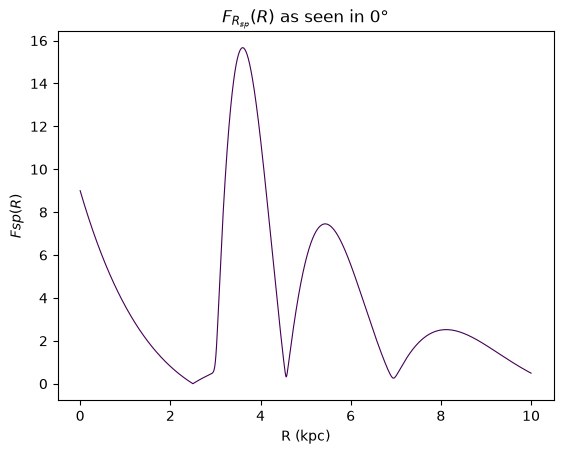

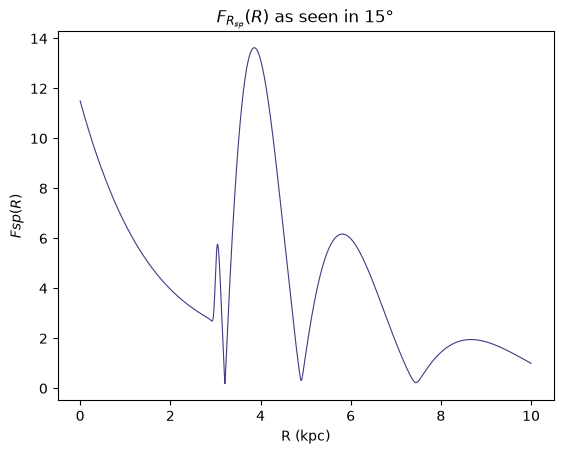

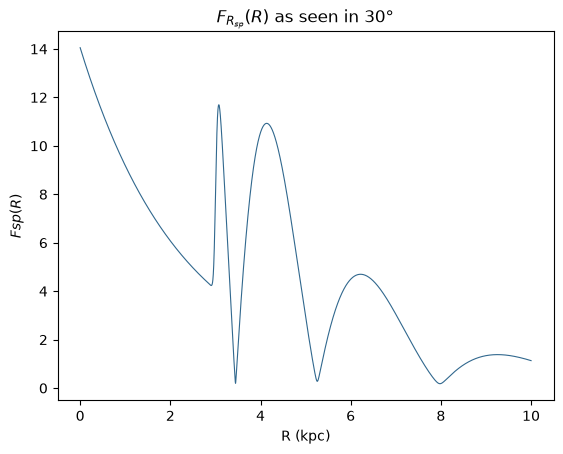

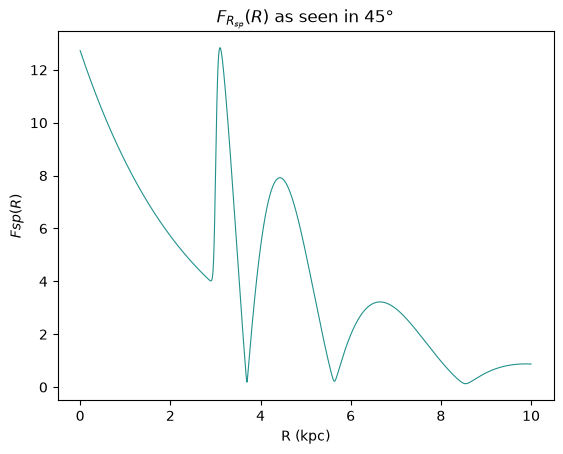

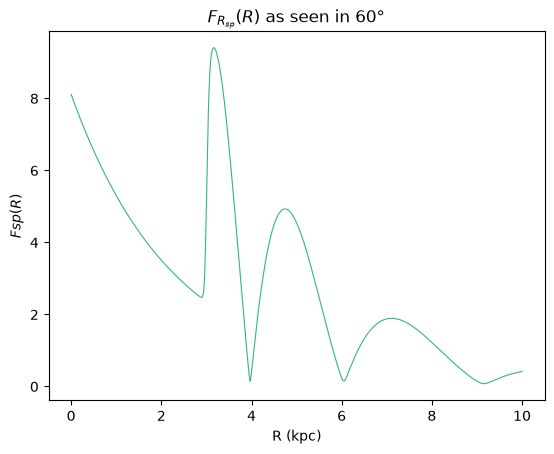

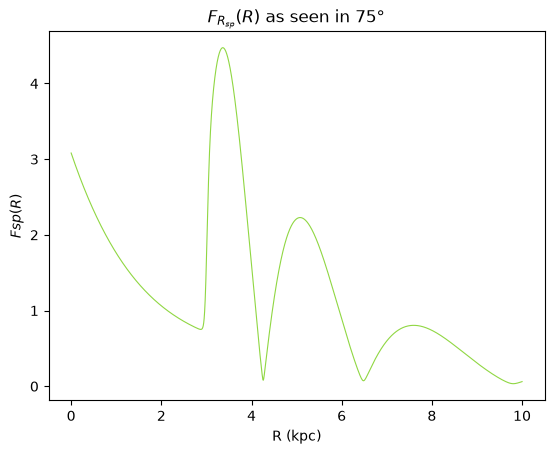

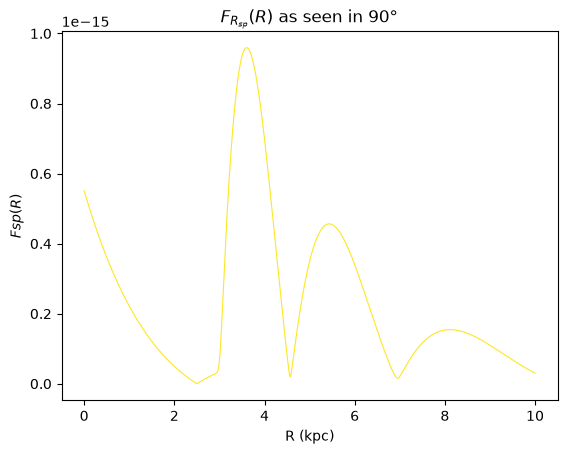

In [24]:
colors = plt.cm.viridis(np.linspace(0, 1, 7))

for i in range(len(theta)):
    plt.figure()
    plt.plot(R, radial_forces[str(theta_[i])], lw = 0.8, color = colors[i])

    plt.xlabel(r"R (kpc)")
    plt.ylabel(r"$F{sp}(R)$")
    plt.title(r"$F_{R_{sp}}(R)$" + f" as seen in {15*i}°")

    plt.show()